### Geometric Brownian Motion

$$
dS(t) = \mu S(t)dt + \sigma S(t) dW(t),
$$
where $W(t)$ is a Wiener process, $\mu, \sigma$ are constants.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from copy import copy

In [4]:
mu = 0.1
sigma = 1
N_traj = 1000
S0 = np.ones(N_traj)
dts = np.array([1, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001])

def GBM_sim(N_traj, S0, mu, sigma, dts):
    results = {}

    for dt in dts:
        N = int(1 / dt)
        times = np.linspace(0, 1, N + 1)

        dW = np.sqrt(dt) * np.random.randn(N, N_traj)
        W = np.vstack([np.zeros(N_traj), np.cumsum(dW, axis=0)])

        S_em = np.zeros((N + 1, N_traj))
        S_em[0] = S0

        for n in range(N):
            S_em[n + 1] = (
                S_em[n]
                + mu * S_em[n] * dt
                + sigma * S_em[n] * dW[n]
            )

        S_exact = S0 * np.exp(
            (mu - sigma**2 / 2) * times[:, None]
            + sigma * W
        )

        error = np.sqrt(np.mean((S_em[-1] - S_exact[-1])**2))

        results[dt] = {
            "times": times,
            "S_em": S_em,
            "S_exact": S_exact,
            "error": error,
            "mean_em": np.mean(S_em, axis=1),
            "var_em": np.var(S_em, axis=1),
            "mean_exact": np.mean(S_exact, axis=1),
            "var_exact": np.var(S_exact, axis=1)
        }

    return results

results = GBM_sim(N_traj, S0, mu, sigma, dts)





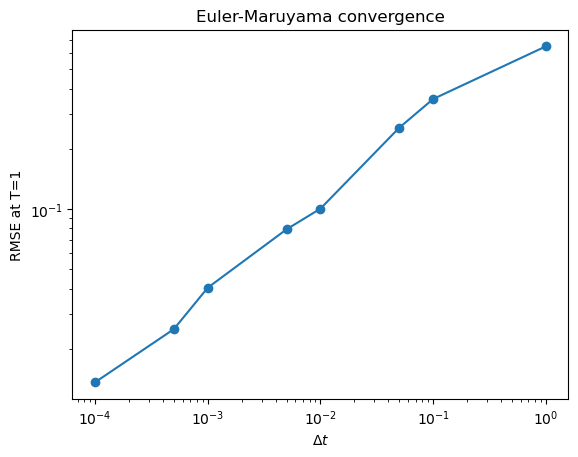

In [5]:
errors = [results[dt]["error"] for dt in dts]

plt.loglog(dts, errors, 'o-')
plt.xlabel(r'$\Delta t$')
plt.ylabel('RMSE at T=1')
plt.title('Euler-Maruyama convergence')
plt.show()